# Control supervisorio con DESlab: dos máquinas y un buffer

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nebisman/deslab-py3/blob/main/notebooks/factory_io/LCS_pequena_factoria_st.ipynb)

Problema clásico de control supervisorio (Ramadge y Wonham): dos máquinas en serie conectadas
por un buffer de capacidad 1. Después de sintetizar el supervisor se genera con DESlab el
programa en texto estructurado (ST) que lo ejecuta en un PLC con OpenPLC, se revisa ese
programa y se sigue su ejecución scan por scan.

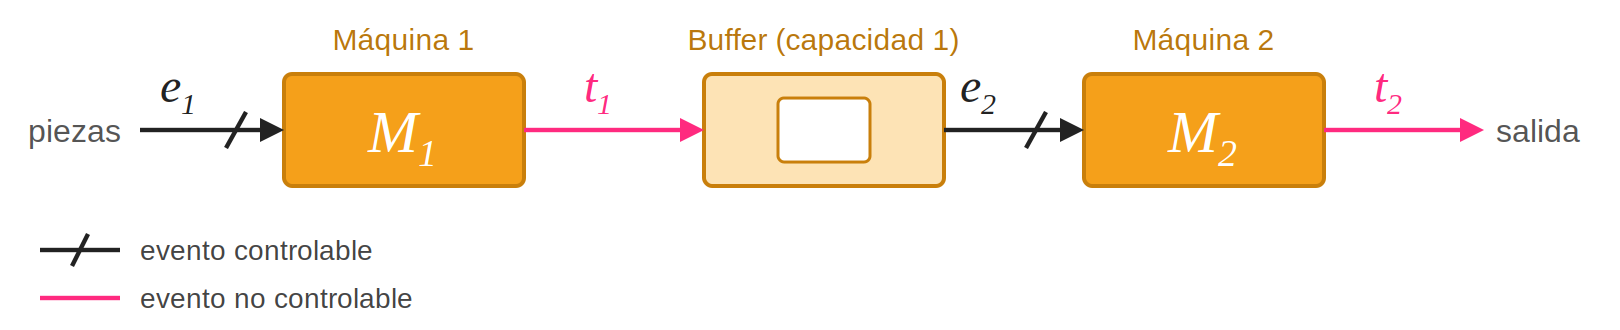

En la figura los eventos controlables ($e_1$, $e_2$) llevan una rayita sobre el arco y los no
controlables ($t_1$, $t_2$) van en color rosado, como en los dibujos de DESlab.

La máquina $M_1$ toma una pieza, la procesa y la deja en el buffer; la máquina $M_2$ toma la pieza
del buffer y la procesa. Se busca un supervisor que evite que el buffer se desborde ($M_1$ deja una
pieza con el buffer lleno) y que $M_2$ arranque con el buffer vacío, restringiendo lo menos posible
el funcionamiento de las máquinas y sin bloquear el sistema.

Pasos:

1. Modelar la planta $G = M_1 \parallel M_2$ e indicar qué eventos son controlables.
2. Modelar la especificación $B$ (el buffer) y construir $H = G \parallel B$, que marca el lenguaje deseado $K = L_m(H)$.
3. Verificar si $K$ es controlable.
4. Calcular el supremo sublenguaje controlable $K^{\uparrow C}$ con `supcontrollable`: el autómata
   que lo marca es el supervisor $S$, el menos restrictivo y no bloqueante.
5. Generar con `generate_ST_OPENPLC` el programa ST para OpenPLC, revisarlo y seguir su
   ejecución scan por scan.

In [ ]:
#@title Instalación de DESlab desde GitHub (ejecute esta celda primero)
import importlib, json, shutil, subprocess, sys
from importlib.metadata import distribution

# programas de graphviz (Colab normalmente ya los trae instalados)
if shutil.which("dot") is None:
    subprocess.run("apt-get -qq install -y graphviz > /dev/null", shell=True)

%pip install -q networkx graphviz
# se reinstala siempre la última versión de DESlab que está en GitHub
%pip install -q --force-reinstall --no-deps --no-cache-dir git+https://github.com/nebisman/deslab-py3.git

# si la celda se ejecuta de nuevo, DESlab se descarga de la memoria para
# que la siguiente celda importe la versión recién instalada
importlib.invalidate_caches()
for name in [m for m in sys.modules if m == "deslab" or m.startswith("deslab.")]:
    del sys.modules[name]

info = json.loads(distribution("deslab").read_text("direct_url.json") or "{}")
print("DESlab instalado desde el commit", info.get("vcs_info", {}).get("commit_id", "?")[:7])

In [2]:
from deslab import *

## 1. Planta: pequeña fábrica sin fallas

Cada máquina $M_i$ tiene dos estados, $D$ (desocupada, inicial y marcado) y $O$ (ocupada), y dos
eventos:

| Evento | Significado | Tipo |
|---|---|---|
| $e_i$ | la máquina toma una pieza y empieza a trabajar | controlable |
| $t_i$ | la máquina termina y entrega la pieza | no controlable |


**Eventos controlables en DESlab.** Se indican con el parámetro `Sigcon`. Si se omite, DESlab
considera *todos* los eventos controlables, y la composición paralela une los conjuntos `Sigcon`
de los componentes; por eso hay que darlo en cada máquina.

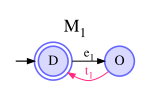

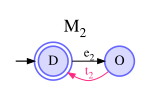

In [3]:
syms('D O B0 B1 e1 t1 e2 t2')
table1 = [(e1, 'e_1'), (t1, 't_1'), (e2, 'e_2'), (t2, 't_2')]

X1 = [D, O]
E1 = [e1, t1]
table1 = [(e1, 'e_1'), (t1, 't_1')]
table2 = [(e2, 'e_2'), (t2, 't_2')]



X2 = [D, O]
E2 = [e2, t2]   
T1 = [(D, e1, O), (O, t1, D)]
T2 = [(D, e2, O), (O, t2, D)]
M1 = fsa(X1, E1, T1, [D], [D], table1, Sigcon=[e1], name='$M_1$')
M2 = fsa(X2, E2, T2, [D], [D], table2, Sigcon=[e2], name='$M_2$')
draw(M1, M2)

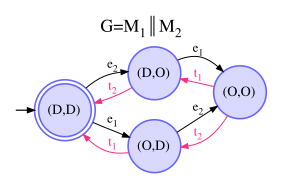

In [4]:
G = (M1 // M2).setpar(name='$G = M_1 \\parallel M_2$')
draw(G)


## 2. Especificación: buffer de capacidad 1

El buffer  $B$ tiene dos estados: $B0$ (vacío) y $B1$ (lleno). $t_1$ indica que $M_1$ deja una pieza y  $e_2$ indica que $M_2$ la retira.
Como $B$ no tiene $t_1$ en el estado $B1$ ni $e_2$ en el estado $B0$, prohíbe el desborde y que
$M_2$ arranque sin pieza. En $B$ solo $e_2$ es controlable (`Sigcon=[e2]`): si se omite,
DESlab considera controlables todos los eventos de $B$, y $H$ y el supervisor heredarían
$t_1$ como controlable.

$H = G \parallel B$ combina la planta con la especificación y marca el lenguaje deseado $K = L_m(H)$.


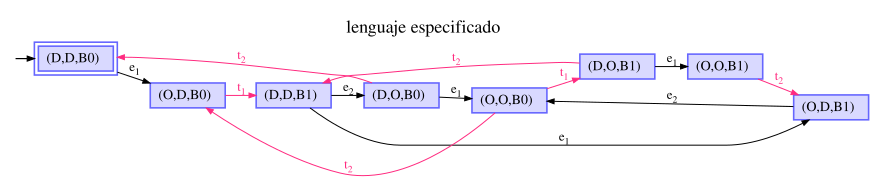

In [5]:
XB = [B0, B1]
EB = [t1, e2]
TB = [(B0, t1, B1), (B1, e2, B0)]
tableB = [(t1, 't_1'), (e2, 'e_2')]
B = fsa(XB, EB, TB, [B0], [B0], table=tableB, Sigcon=[e2], name='$B$ -- bufer', type='specification')

H = (G // B).setpar(name='lenguaje especificado', style='verifier')
draw(H)



## 3. ¿Es controlable $K$?

$K$ es controlable con respecto a $L(G)$ y a los eventos no controlables $\Sigma_{uc}$ si
$\overline{K}\,\Sigma_{uc} \cap L(G) \subseteq \overline{K}$: la especificación nunca debe prohibir un
evento no controlable que la planta puede ejecutar, porque el supervisor no lo puede impedir.
`iscontrollable(H, G)` hace esa prueba. La celda lista además los estados de $H$ donde falla.

In [6]:
print('¿K es controlable?', iscontrollable(H, G))

Sigma_uc = G.Sigma - G.Sigcon
for xh in sorted(H.X):
    m1 , m2 , b  = xh
    prohibidos = (G.Gamma((m1,m2)) & Sigma_uc) - H.Gamma(xh)
    if prohibidos:
        print(f'en el estado {xh} H prohíbe {sorted(prohibidos)}, que no es controlable')



¿K es controlable? False
en el estado ('O', 'D', 'B1') H prohíbe ['t1'], que no es controlable
en el estado ('O', 'O', 'B1') H prohíbe ['t1'], que no es controlable


En los dos estados la máquina 1 trabaja con el buffer lleno: cuando termine ($t_1$, no
controlable) el buffer se desborda, y el supervisor no lo puede evitar. Hay que actuar antes,
deshabilitando $e_1$ cuando el buffer está lleno. Eso es lo que calcula el sublenguaje
controlable supremo.

## 4. Supervisor: sublenguaje controlable supremo



`supcontrollable(H, G)` devuelve un autómata que marca $K^{\uparrow C}$, el mayor sublenguaje
controlable de $K$.

`supcontrollable` numera los estados si se usa con `renamestates=True`


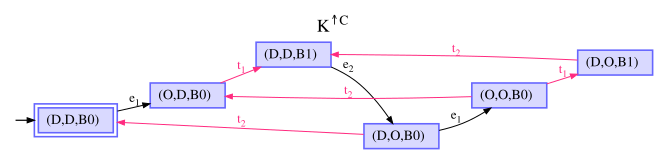

In [7]:
SUP = supcontrollable(H, G).setpar(style='verifier')

#S = supcontrollable(H, G, verbose=True, renamestates=True) #si quieres que los estados de S se renombren con números consecutivos
draw(SUP)

## 5. Del supervisor al programa del PLC

Un PLC ejecuta su programa en ciclos llamados *scans*: lee las entradas, ejecuta el programa
completo y escribe las salidas. `generate_ST_OPENPLC` convierte el supervisor en un programa en
texto estructurado (ST, norma IEC 61131-3) que OpenPLC ejecuta cada 20 ms. En ese programa:

* una variable entera, `state[0]`, guarda el estado actual de $SUP$;
* un evento **no controlable** ($t_1$, $t_2$) es algo que el PLC **observa** en una entrada; cuando
  lo ve, actualiza `state[0]` con la transición de $SUP$;
* un evento **controlable** ($e_1$, $e_2$) es algo que el PLC **hace** escribiendo una salida: en
  cada estado escribe las órdenes de los eventos que $SUP$ habilita y actualiza `state[0]` cuando
  la orden queda escrita.

El supervisor solo dice *qué* eventos se permiten en cada estado. Para obtener el programa hay que
definir además:

1. el contrato con las máquinas: qué señales hay y cómo se comportan (sección 5.1);
2. qué señal corresponde a cada evento, con el diccionario `actuators` (sección 5.2);
3. lo que el modelo no describe; aquí, apagar las órdenes de arranque con los autómatas de
   rearme (sección 5.3).

### 5.1 Contrato con las máquinas

Cada máquina $M_i$ se conecta al PLC con una salida y una entrada:

| Señal | Tipo | Dirección | Significado |
|---|---|---|---|
| `Cmd_M1`, `Cmd_M2` | salida del PLC | `%QX0.0`, `%QX0.1` | orden de arranque: 1 = tomar una pieza y trabajar |
| `Fin_M1`, `Fin_M2` | entrada del PLC | `%IX0.0`, `%IX0.1` | la máquina terminó su pieza |

En las direcciones de la norma, `%IX0.0` es el bit 0 del byte 0 de entradas y `%QX0.0` el bit 0
del byte 0 de salidas. Son direcciones de ejemplo: deben coincidir con la configuración de
entradas y salidas del runtime OpenPLC o del simulador que se use.

Las máquinas cumplen este contrato:

1. **Inicio.** Las órdenes y las señales de fin están en 0, las dos máquinas están desocupadas y el
   buffer está vacío: es el estado inicial de $SUP$.
2. **Arranque ($e_i$).** Cuando `Cmd_Mi` pasa de 0 a 1, la máquina toma una pieza y trabaja. El PLC
   mantiene `Cmd_Mi = 1` mientras la máquina trabaja.
3. **Fin ($t_i$).** Al terminar, la máquina pone `Fin_Mi = 1` y lo mantiene hasta que el PLC baje
   la orden. La pieza de $M_1$ queda en el buffer.
4. **Rearme.** Cuando ve `Cmd_Mi = 0`, la máquina baja `Fin_Mi` en cuanto puede recibir otra pieza.
   Mientras `Fin_Mi = 1`, el PLC no debe encender `Cmd_Mi`.

Así, $e_i$ es el flanco de subida de `Cmd_Mi` y $t_i$ el flanco de subida de `Fin_Mi`.

**Supuestos de tiempo.** El programa corre en una tarea de 20 ms y cada señal dura al menos un
scan. Las dos máquinas no terminan en el mismo scan: el programa procesa a lo sumo una transición
no controlable de $SUP$ por scan, y el flanco de `Fin_Mi` solo se detecta durante un scan, así que
un segundo fin simultáneo se perdería. Si el proceso permite fines simultáneos, hay que capturarlos
y procesarlos uno por scan. Tampoco se contempla reiniciar el PLC a mitad de un ciclo.

### 5.2 Eventos y señales: el diccionario `actuators`

`actuators` asocia cada evento con una señal del PLC mediante un texto con campos separados por
`:`. Aunque se llama así, también contiene los sensores. Lo que el programa hace con cada
asociación depende de si el evento es controlable en el autómata que lo usa: si lo es, el
programa **escribe** la señal; si no, la **lee** como condición de una transición.

| Formato | Ejemplo | Declaración en el programa | Evento controlable: el PLC escribe | Evento no controlable: el PLC observa |
|---|---|---|---|---|
| `Var:ON:dirección` | `'Cmd_M1:ON:%QX0.0'` | `Cmd_M1 AT %QX0.0 : BOOL;` | `Cmd_M1 := 1;` | `Cmd_M1` (nivel 1) |
| `Var:OFF:dirección` | `'Fin_M1:OFF:%IX0.0'` | `Fin_M1 AT %IX0.0 : BOOL;` | `Fin_M1 := 0;` | `NOT Fin_M1` (nivel 0) |
| `Var:ON` o `Var:OFF` | `'Cmd_M1:OFF'` | ninguna: otra asociación ya declaró `Cmd_M1` con su dirección | `Cmd_M1 := 0;` | `NOT Cmd_M1` |
| `RE_Nombre:Var:dirección` | `'RE_Fin_M1:Fin_M1:%IX0.0'` | la variable `Fin_M1 AT %IX0.0 : BOOL;`, el detector `RE_Fin_M1 : R_TRIG;` y su llamada `RE_Fin_M1(CLK:= Fin_M1);` | no se permite | `RE_Fin_M1.Q`, que vale 1 solo en el scan en que `Fin_M1` pasa de 0 a 1 |

Con el prefijo `FE_` en lugar de `RE_` el detector es un `F_TRIG` (flanco de bajada). Con varios
supervisores se usan además variables internas `INTERN_k:ON` e `INTERN_k:OFF`, sin dirección; el
notebook de la pequeña fábrica con averías muestra ese caso.

Reglas que conviene recordar:

* Todo evento de $SUP$ y de los autómatas auxiliares necesita una asociación. Si falta alguna, el
  generador se detiene y la nombra.
* Un evento controlable necesita una asociación `ON` u `OFF`: el PLC solo puede ejecutar un evento
  escribiendo un nivel.
* Cada variable se declara una sola vez. La primera asociación que la nombra lleva la dirección y
  las demás, como `'Cmd_M1:OFF'`, la usan sin dirección; por eso deben ir después en el diccionario.
* Las salidas conservan su valor: `Cmd_M1 := 1;` deja la orden encendida hasta que otra escritura
  la apague. El generador no crea pulsos por su cuenta (sección 5.3).

Para los eventos de $SUP$:

| Evento | Tipo | Asociación | En el programa |
|---|---|---|---|
| $e_1$ | controlable | `'Cmd_M1:ON:%QX0.0'` | escribe `Cmd_M1 := 1;` |
| $e_2$ | controlable | `'Cmd_M2:ON:%QX0.1'` | escribe `Cmd_M2 := 1;` |
| $t_1$ | no controlable | `'RE_Fin_M1:Fin_M1:%IX0.0'` | observa `RE_Fin_M1.Q` |
| $t_2$ | no controlable | `'RE_Fin_M2:Fin_M2:%IX0.1'` | observa `RE_Fin_M2.Q` |

Los otros cuatro eventos del diccionario son de los autómatas de rearme de la sección 5.3.

In [8]:
syms('apaga1 lista1 apaga2 lista2')

actuators = {
    # eventos controlables de SUP: escribir 1 en la orden de arranque
    e1: 'Cmd_M1:ON:%QX0.0',
    e2: 'Cmd_M2:ON:%QX0.1',
    # eventos no controlables de SUP: flanco de subida de la señal de fin
    t1: 'RE_Fin_M1:Fin_M1:%IX0.0',
    t2: 'RE_Fin_M2:Fin_M2:%IX0.1',
    # eventos de los autómatas de rearme (sección 5.3)
    apaga1: 'Cmd_M1:OFF',          # escribir 0 en la orden; Cmd_M1 ya tiene dirección
    apaga2: 'Cmd_M2:OFF',
    lista1: 'Fin_M1:OFF:%IX0.0',   # observar Fin_M1 = 0: M1 puede recibir otra pieza
    lista2: 'Fin_M2:OFF:%IX0.1',
}

### 5.3 Apagar las órdenes: autómatas de rearme

$SUP$ enciende `Cmd_Mi` para producir $e_i$, pero nada en $SUP$ la apaga: en el modelo $e_i$ es un
evento instantáneo y no existe el evento "apagar la orden". Si nadie la apaga, la orden sigue en 1 y
la máquina no se rearma (punto 4 del contrato). El rearme se programa con un autómata auxiliar por
máquina, que no participa en la síntesis:

* en el estado `espera` observa $t_i$, el mismo flanco de fin que usa $SUP$, y pasa a `rearme`;
* en `rearme` ejecuta `apaga_i` (`Cmd_Mi := 0`) en cada scan; por eso `apaga_i` es un lazo y es su
  único evento controlable (`Sigcon=[apaga_i]`);
* cuando observa `lista_i` (`Fin_Mi = 0`), la máquina ya está lista y el autómata vuelve a `espera`.

Los dos estados son marcados porque el rearme no impone una condición de terminación.

Los autómatas auxiliares se pasan en `Isolated`. El generador escribe sus acciones después de
las de $SUP$, así que en un mismo scan `Cmd_Mi := 0` prevalece sobre `Cmd_Mi := 1`. Además, $SUP$
avanza con $e_i$ solo si `Cmd_Mi` sigue en 1 después de esas escrituras: mientras dura el rearme,
$SUP$ pide el arranque en cada scan, pero no lo cuenta hasta que la máquina está lista. La sección 7
muestra este caso. Las parejas de eventos con lógica directa (`event_pairs`) no se usan aquí.

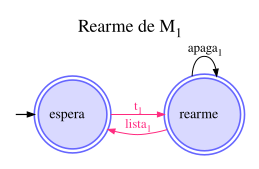

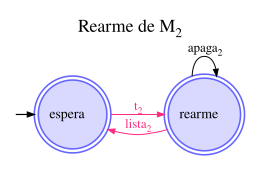

In [9]:
Rearme_M1 = fsa(['espera', 'rearme'], [t1, apaga1, lista1],
                [('espera', t1, 'rearme'), ('rearme', apaga1, 'rearme'), ('rearme', lista1, 'espera')],
                ['espera'], ['espera', 'rearme'],
                table=[(t1, 't_1'), (apaga1, 'apaga_1'), (lista1, 'lista_1')],
                Sigcon=[apaga1], name='Rearme de $M_1$')
Rearme_M2 = fsa(['espera', 'rearme'], [t2, apaga2, lista2],
                [('espera', t2, 'rearme'), ('rearme', apaga2, 'rearme'), ('rearme', lista2, 'espera')],
                ['espera'], ['espera', 'rearme'],
                table=[(t2, 't_2'), (apaga2, 'apaga_2'), (lista2, 'lista_2')],
                Sigcon=[apaga2], name='Rearme de $M_2$')
draw(Rearme_M1, Rearme_M2)

### 5.4 Parámetros de `generate_ST_OPENPLC`

| Parámetro | Qué recibe | En este ejemplo |
|---|---|---|
| `supervisors` | lista de supervisores; cada uno tiene su variable de estado `state[k]` en el programa | `[SUP]`, con `state[0]` |
| `plants` | una planta por supervisor, en el mismo orden; de ella se toma qué eventos son controlables | `[G]` |
| `actuators` | el diccionario de la sección 5.2 | `actuators` |
| `namest` | nombre del archivo `.st`, sin la extensión | `'pequena_factoria'` |
| `Mask` | señales que se copian a otras salidas al final de cada scan, por ejemplo `{'Cmd_M1': [('Piloto_M1', '%QX0.2')]}` | `{}` |
| `Isolated` | lista de autómatas auxiliares; cada uno tiene su `state[k]`, después de los supervisores | `[Rearme_M1, Rearme_M2]`, con `state[1]` y `state[2]` |
| `initial` | evento de una entrada que habilita el control, por ejemplo un pulsador de marcha; con `'null'` el control empieza en el primer scan | `'null'` |
| `output_dir` | carpeta donde se escribe el archivo; se crea si no existe | `ST_Generated` |
| `event_order` | orden de los eventos al numerar los estados y al escribir las ramas | `[e1, t1, e2, t2, apaga1, lista1, apaga2, lista2]` |

La función devuelve el texto del programa y lo escribe en `output_dir/namest.st`, reemplazando
un archivo anterior con el mismo nombre.

**Eventos controlables.** El generador toma la clasificación de `plants`. Con un solo supervisor
`plants` se puede omitir y entonces usa `SUP.Sigcon`; por eso importa haber dado `Sigcon=[e2]` en
$B$. Pasar `plants=[G]` evita depender de eso.

**Numeración de los estados.** En el programa los estados de cada autómata son números. El
generador los numera recorriendo el autómata en anchura desde el estado inicial, que recibe el 0,
y en cada estado sigue los eventos en el orden de `event_order`. Cambiar el orden cambia los
números, no el comportamiento. La sección 6 muestra la correspondencia.

In [10]:
from pathlib import Path

orden_eventos = [e1, t1, e2, t2, apaga1, lista1, apaga2, lista2]

# todo evento de SUP y de los rearmes necesita una señal
faltan = set(SUP.Sigma | Rearme_M1.Sigma | Rearme_M2.Sigma) - set(actuators)
assert not faltan, f'eventos sin señal: {faltan}'

carpeta = Path('ST_Generated')
st = generate_ST_OPENPLC([SUP], plants=[G], actuators=actuators, namest='pequena_factoria',
                         Mask={}, Isolated=[Rearme_M1, Rearme_M2], initial='null',
                         output_dir=carpeta, event_order=orden_eventos)
archivo = carpeta / 'pequena_factoria.st'
assert archivo.read_text(encoding='utf-8') == st
print('programa guardado en', archivo)
print('líneas:', len(st.splitlines()))

programa guardado en ST_Generated/pequena_factoria.st
líneas: 127


## 6. Revisión del programa generado

La celda siguiente muestra el programa con números de línea. El texto entre `(*` y `*)` son
comentarios que escribe el generador: al comienzo, lo que hace cada scan y qué autómata es cada
`state[k]`; en cada variable, qué guarda y a qué eventos corresponde; y al final de cada transición
y de cada orden, su evento. El programa tiene tres partes.

**Declaraciones (líneas 1 a 54).**

* Líneas 1 a 22: el bloque `random_number`, con código C propio de OpenPLC. Sirve para elegir al
  azar cuando un supervisor habilita varios eventos controlables en un mismo estado. $SUP$ nunca
  habilita más de uno, así que el bloque se declara y se llama en las líneas 51 a 54, pero su valor
  no se usa.
* Líneas 23 a 31: el comentario inicial, con los pasos de cada scan y la lista de autómatas.
* Líneas 33 a 40: variables internas. `state` guarda el estado de cada autómata: `state[0]` es
  $SUP$ y `state[1]` y `state[2]` son los rearmes de $M_1$ y $M_2$; `state[3]` no se usa. `RE_Fin_M1`
  y `RE_Fin_M2` son los detectores de flanco.
* Líneas 41 a 47: las entradas y salidas con sus direcciones.
* Líneas 48 a 50: los detectores de flanco se actualizan al principio de cada scan.

**Lo que hace cada scan (líneas 55 a 114).** Las variables enteras valen 0 al encender el PLC, así
que todos los autómatas empiezan en su estado inicial.

1. Líneas 55 a 67: transiciones **no controlables** de $SUP$. Cada rama `state[0] = origen &
   RE_Fin_Mi.Q` es una transición con $t_i$. Como forman una cadena `IF … ELSIF`, en cada scan se
   ejecuta a lo sumo una: de ahí el supuesto de un fin por scan.
2. Líneas 69 a 81: transiciones de los rearmes, que pasan a `rearme` (1) con el flanco de fin y
   vuelven a `espera` (0) con `NOT Fin_Mi`.
3. Líneas 83 a 93: **acciones de $SUP$**. En cada estado con eventos controlables habilitados escribe
   sus órdenes: en los estados 0 y 3 enciende `Cmd_M1` ($e_1$) y en el 2 enciende `Cmd_M2` ($e_2$).
   En los demás estados no escribe nada y las órdenes conservan su valor; en el estado 1, por
   ejemplo, `Cmd_M1` sigue en 1 mientras $M_1$ trabaja.
4. Líneas 95 a 105: acciones de los rearmes, que apagan la orden en el estado `rearme`. Van después
   de las de $SUP$ y por eso prevalecen.
5. Líneas 106 a 114: transiciones **controlables** de $SUP$. Si la orden quedó en 1, $SUP$ avanza con
   $e_i$. El lazo `apaga_i` de los rearmes no cambia de estado y no produce ninguna rama.

Al final del scan el PLC copia `Cmd_M1` y `Cmd_M2` en las salidas físicas.

**Configuración (líneas 121 a 127).** Una tarea periódica de 20 ms, `task0`, ejecuta el programa
`supcon`.

In [11]:
for numero, linea in enumerate(st.splitlines(), 1):
    print(f'{numero:3}  {linea.expandtabs(4)}')

# en Colab se descarga el archivo; en Jupyter queda un enlace
try:
    from google.colab import files
    files.download(str(archivo))
except ImportError:
    from IPython.display import FileLink, display
    display(FileLink(str(archivo)))

  1  (* OpenPLC random number (C code), used to pick one of several orders *)
  2  FUNCTION_BLOCK random_number
  3      VAR_INPUT
  4          IN : BOOL;
  5      END_VAR
  6      VAR
  7          M : BOOL;
  8          INIT : BOOL;
  9      END_VAR
 10      VAR_OUTPUT
 11          OUT : DINT;
 12      END_VAR
 13  
 14      IF INIT = 0 THEN
 15          {#include <stdio.h>}
 16          {#include <stdlib.h>}
 17          IN := 1;
 18      END_IF;
 19      IF M = 0 and IN = 1 THEN
 20          {SetFbVar(OUT,rand())}
 21      END_IF;
 22  END_FUNCTION_BLOCK
 23  (* Controller generated by DESlab (generate_ST_OPENPLC). Every scan it: *)
 24  (* 1. computes the input edges and a random number *)
 25  (* 2. each automaton moves with at most one uncontrollable event *)
 26  (* 3. each automaton writes the orders enabled in its state; if there are several, it picks one at random *)
 27  (* 4. each automaton moves with the order that was given (controllable event) *)
 28  (* The states of ea

ST_Generated/pequena_factoria.st

### Comprobar el programa contra el supervisor

La revisión anterior se puede hacer de forma automática. La celda siguiente:

1. numera los estados de $SUP$ como el generador (en anchura, con el orden de `event_order`);
2. extrae del programa todas las ramas `state[0] = origen & condición THEN state[0] := destino` y
   comprueba que son exactamente las transiciones de $SUP$, cada una con la señal de su evento;
3. extrae el bloque `CASE state[0]` y comprueba que en cada estado se escriben justo las órdenes de
   los eventos controlables que $SUP$ habilita.

La tabla resultante es la lectura del programa en términos del supervisor.

In [12]:
import re

def numerar(S, orden):
    """numeración del generador: en anchura desde el estado inicial, eventos según `orden`"""
    clave = lambda e: (0, orden.index(e)) if e in orden else (1, str(e))
    inicial = next(iter(S.X0))
    numero, pendientes = {inicial: 0}, [inicial]
    for x in pendientes:
        for e in sorted(S.Gamma(x), key=clave):
            if S.delta(x, e) not in numero:
                numero[S.delta(x, e)] = len(numero)
                pendientes.append(S.delta(x, e))
    return numero

numero = numerar(SUP, orden_eventos)
programa = re.sub(r' ?\(\*.*?\*\)', '', st)   # el programa sin comentarios
condicion = {e1: 'Cmd_M1', e2: 'Cmd_M2', t1: 'RE_Fin_M1.Q', t2: 'RE_Fin_M2.Q'}
escritura = {e1: 'Cmd_M1 := 1;', e2: 'Cmd_M2 := 1;'}

# 2. transiciones de SUP en el programa
en_programa = {(int(a), c, int(b)) for a, c, b in
               re.findall(r'state\[0\] = (\d+) & ([\w.]+) THEN\s+state\[0\] := (\d+);', programa)}
en_SUP = {(numero[x], condicion[e], numero[SUP.delta(x, e)]) for x in SUP.X for e in SUP.Gamma(x)}
assert en_programa == en_SUP

# 3. órdenes que escribe el bloque CASE state[0]
bloque = re.search(r'CASE state\[0\] OF(.*?)END_CASE;', programa, re.S)[1]
escritas = dict(re.findall(r'(\d+):\s*(.+)', bloque))
for x, k in numero.items():
    esperadas = [escritura[e] for e in SUP.Gamma(x) if e in G.Sigcon]
    assert len(esperadas) <= 1   # nunca dos eventos controlables a la vez: no se usa el azar
    assert escritas.get(str(k)) == (esperadas[0] if esperadas else None)

print(f"{'state[0]':9} {'estado de SUP':16} {'habilitados':13} escribe")
for x, k in sorted(numero.items(), key=lambda par: par[1]):
    print(f"{k:<9} {'(' + ', '.join(x) + ')':16} {', '.join(sorted(SUP.Gamma(x))):13} "
          f"{escritas.get(str(k), '-')}")

state[0]  estado de SUP    habilitados   escribe
0         (D, D, B0)       e1            Cmd_M1 := 1;
1         (O, D, B0)       t1            -
2         (D, D, B1)       e2            Cmd_M2 := 1;
3         (D, O, B0)       e1, t2        Cmd_M1 := 1;
4         (O, O, B0)       t1, t2        -
5         (D, O, B1)       t2            -


## 7. Ejecución del supervisor, scan por scan

La tabla muestra los primeros 14 scans del programa con dos máquinas que cumplen el contrato:
$M_1$ tarda 2 scans en procesar una pieza, $M_2$ tarda 3, y cada máquina baja su señal de fin un
scan después de ver la orden apagada. Las columnas de entradas son los valores que lee el PLC en
el scan y las demás son los valores al final del scan. Se obtuvo ejecutando el programa compilado
con MatIEC, el compilador de OpenPLC (sección 8).

| Scan | `Fin_M1` | `Fin_M2` | Eventos | `state[0]` | Estado de $SUP$ | `state[1]` | `state[2]` | `Cmd_M1` | `Cmd_M2` |
|---|---|---|---|---|---|---|---|---|---|
| 1 | 0 | 0 | $e_1$ | 1 | (O, D, B0) | 0 | 0 | 1 | 0 |
| 2 | 0 | 0 | — | 1 | (O, D, B0) | 0 | 0 | 1 | 0 |
| 3 | 1 | 0 | $t_1$, $e_2$ | 3 | (D, O, B0) | 1 | 0 | 0 | 1 |
| 4 | 1 | 0 | — | 3 | (D, O, B0) | 1 | 0 | 0 | 1 |
| 5 | 0 | 0 | $e_1$ | 4 | (O, O, B0) | 0 | 0 | 1 | 1 |
| 6 | 0 | 1 | $t_2$ | 1 | (O, D, B0) | 0 | 1 | 1 | 0 |
| 7 | 1 | 1 | $t_1$ | 2 | (D, D, B1) | 1 | 1 | 0 | 0 |
| 8 | 1 | 0 | $e_2$ | 3 | (D, O, B0) | 1 | 0 | 0 | 1 |
| 9 | 0 | 0 | $e_1$ | 4 | (O, O, B0) | 0 | 0 | 1 | 1 |
| 10 | 0 | 0 | — | 4 | (O, O, B0) | 0 | 0 | 1 | 1 |
| 11 | 1 | 0 | $t_1$ | 5 | (D, O, B1) | 1 | 0 | 0 | 1 |
| 12 | 1 | 1 | $t_2$ | 2 | (D, D, B1) | 1 | 1 | 0 | 0 |
| 13 | 0 | 1 | — | 2 | (D, D, B1) | 0 | 1 | 0 | 0 |
| 14 | 0 | 0 | $e_2$ | 3 | (D, O, B0) | 0 | 0 | 0 | 1 |

Lo que conviene observar:

* **Scan 1.** En el estado 0 $SUP$ escribe `Cmd_M1 := 1` y, como la orden queda en 1, avanza al
  estado 1 en el mismo scan. $M_1$ arranca.
* **Scan 3.** Sube `Fin_M1`: $SUP$ pasa por $t_1$ al estado 2 (buffer lleno) y `Rearme_M1` pasa a
  `rearme`, que apaga `Cmd_M1`. En el mismo scan $SUP$ escribe `Cmd_M2 := 1` y avanza con $e_2$:
  $M_2$ toma la pieza.
* **Scan 4.** En el estado 3 $SUP$ pide otra vez `Cmd_M1 := 1`, pero el rearme la apaga porque
  `Fin_M1` sigue en 1. La orden queda en 0 y $SUP$ no avanza.
* **Scan 5.** `Fin_M1` ya bajó: el rearme vuelve a `espera`, la orden de $SUP$ queda en 1 y $M_1$
  arranca mientras $M_2$ trabaja (estado 4).
* **Scans 7 y 8.** $M_1$ termina con el buffer vacío, pero $M_2$ todavía no se ha rearmado: $SUP$
  espera en el estado 2 hasta que baja `Fin_M2` y entonces arranca $M_2$.
* **Scans 11 a 14.** $M_1$ termina mientras $M_2$ trabaja: el buffer se llena (estado 5) y $SUP$ no
  vuelve a arrancar $M_1$ hasta que $M_2$ tome la pieza en el scan 14.

En ningún scan arranca $M_2$ con el buffer vacío ni termina $M_1$ con el buffer lleno.

## 8. Validación y puesta en marcha

En este notebook se comprobó que $SUP$ es el supervisor controlable y no bloqueante, que el
programa tiene exactamente las transiciones de $SUP$ y que escribe las órdenes que $SUP$ habilita.
La prueba `tests/test_openplc_notebooks.py` del repositorio ejecuta las celdas del notebook y
simula el programa durante 1000 scans en varios escenarios, con máquinas que cumplen el contrato
de la sección 5.1 y tiempos de trabajo y de rearme al azar. En cada scan comprueba que:

* el estado de `state[0]` es el de $SUP$ después de los eventos observados en las entradas y
  salidas;
* el buffer queda entre 0 y 1 y $M_2$ no arranca con el buffer vacío;
* ninguna orden se apaga mientras la máquina trabaja ni se enciende mientras `Fin_Mi = 1`.

La misma prueba revisa que la tabla de la sección 7 coincide con la simulación. El programa también
se tradujo a C con MatIEC, el compilador de OpenPLC, y el ejecutable se probó con las mismas
máquinas simuladas.

Para llevarlo a OpenPLC:

1. Importe el archivo `.st`, compílelo y asigne las direcciones de entrada y salida de su
   runtime. El bloque `random_number` usa código C propio de OpenPLC.
2. Con las máquinas en reposo, el buffer vacío y las entradas en 0, compruebe que solo arranca
   $M_1$ y que $M_2$ arranca después del primer fin de $M_1$.
3. Mantenga `Fin_M1` en 1 varios scans: `Cmd_M1` debe seguir en 0 hasta que lo baje.
4. Llene el buffer mientras $M_2$ trabaja y compruebe que $M_1$ no arranca hasta que $M_2$ tome
   la pieza.
5. Compruebe los supuestos de tiempo de la sección 5.1 con las máquinas o el simulador reales.